<a href="https://colab.research.google.com/github/namvien94/ab-testing-conversion-analysis/blob/main/ab_testing_conversion_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A/B Testing: Conversion Rate Analysis & Experiment Validation

## 1. Data Overview and Quality Checks

### Experiment Overview

This dataset contains user-level data from an A/B test conducted over approximately 2.5 weeks. The experiment compares two versions, **Group A (Control)** and **Group B (Treatment)**, to determine whether their conversion rates differ significantly.

The primary metric is **conversion rate**, defined as the percentage of users who completed the desired action.

### Dataset Description

The dataset contains four columns:

- **`uid`**: Unique user identifier. Each user should appear only once.
- **`date`**: Date of the user's visit during the experiment.
- **`group`**: Experiment variant assigned to the user (A or B).
- **`converted`**: Binary conversion indicator (1 = converted, 0 = did not convert).

In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Load in dataframe
df = pd.read_csv("/content/ab_test_results.csv")
print(df.shape)
df.head(10)

(114933, 4)


,date,group,converted,uid
0,2020-08-15,A,0,397466
1,2020-08-15,A,0,440843
2,2020-08-15,B,0,370065
3,2020-08-15,B,0,370059
4,2020-08-15,B,0,370058
5,2020-08-15,A,0,370054
6,2020-08-15,A,0,348845
7,2020-08-15,A,0,406719
8,2020-08-15,A,0,406778
9,2020-08-15,B,0,370044


### Data Quality Checks

Before analyzing the experiment, we will check for duplicate users, missing values, valid conversion indicators, and correct group assignments to ensure the data is reliable.

In [74]:
# Check missing values
print(df.isna().sum())

# Check duplicate user IDs
print("Duplicate users:", df["uid"].duplicated().sum())

# Check valid groups
print("Valid groups:", df["group"].isin(["A", "B"]).all())

# Check valid conversion values
print("Valid conversions:", df["converted"].isin([0, 1]).all())

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

date         0
group        0
converted    0
uid          0
dtype: int64
Duplicate users: 0
Valid groups: True
Valid conversions: True


In [75]:
summary = df.groupby("group")["converted"].agg(
    users="count",
    conversions="sum",
    conversion_rate="mean"
).reindex(["A", "B"])

summary["conversion_rate"] *= 100

# Calculate proportion of users in each group
summary["group_proportion"] = summary["users"] / summary["users"].sum() * 100

print(summary)

       users  conversions  conversion_rate  group_proportion
group                                                       
A      58583         5329         9.096496         50.971436
B      56350         5748        10.200532         49.028564


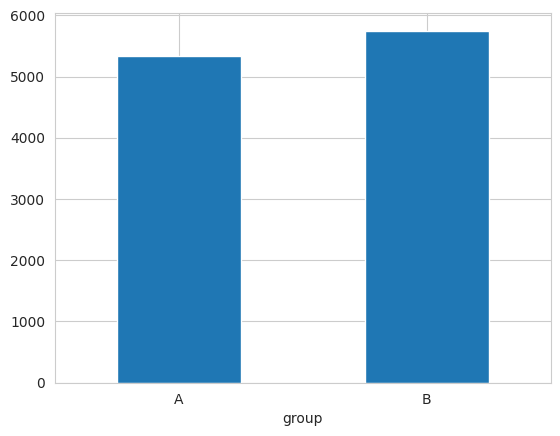

In [82]:
# Plot the number of users in each group
summary["conversions"].plot(kind="bar", rot=0);

In [77]:
from scipy.stats import chisquare

# Number of users in each group
observed = df["group"].value_counts().reindex(["A", "B"])

# Expected allocation: 50% A, 50% B
expected = [len(df) / 2, len(df) / 2]

# Chi-square goodness-of-fit test
chi2_stat, srm_pvalue = chisquare(f_obs=observed, f_exp=expected)

print(f"SRM p-value: {srm_pvalue:.4g}")

if srm_pvalue < 0.01:
    print("Warning: Possible Sample Ratio Mismatch")
else:
    print("No statistically significant SRM detected")

SRM p-value: 4.498e-11


### Sample Ratio Mismatch (SRM) Interpretation

The SRM test returned a p-value of 4.498e-11, which is below the significance level of 0.01. This indicates that the observed allocation between Groups A (50.97%) and B (49.03%) differs significantly from the expected 50/50 split.

Although the percentage difference appears small, it may indicate issues with random assignment, data collection, or experiment execution.

**Recommendation:** Investigate the cause of the mismatch before relying on the A/B test results to make a business decision.

## 2. Visualizing Conversion Rates Over Time

We visualize the daily conversion rates for Groups A and B to examine how their performance changes throughout the experiment. This helps us identify trends, unusual fluctuations, and whether one group consistently outperforms the other.

The visualization provides an initial comparison, while statistical testing will determine whether the observed difference is statistically significant.

In [78]:
# Calculate the conversion rate by group and date
cr_time = df.groupby(by=["date", "group"], as_index=False).agg({"converted": ["count", "sum"]})

cr_time["conversion_rate"] = (
    cr_time.converted["sum"] / cr_time.converted["count"]
) * 100

print(cr_time.head())

        date group converted      conversion_rate
                       count  sum                
0 2020-08-15     A      3372  304        9.015421
1 2020-08-15     B      3193  324       10.147197
2 2020-08-16     A      3370  299        8.872404
3 2020-08-16     B      3222  339       10.521415
4 2020-08-17     A      3371  306        9.077425


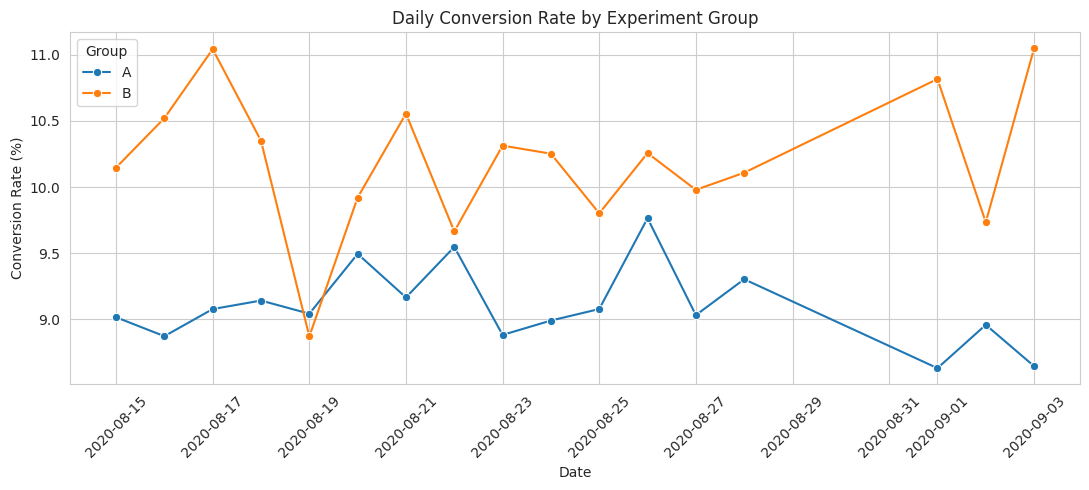

In [79]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=cr_time,
    x="date",
    y="conversion_rate",
    hue="group",
    marker="o"
)

plt.title("Daily Conversion Rate by Experiment Group")
plt.xlabel("Date")
plt.ylabel("Conversion Rate (%)")
plt.legend(title="Group")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Group B consistently achieved higher daily conversion rates than Group A, suggesting better performance throughout most of the experiment.

## 3. Testing and Interpreting Statistical Significance

We use a two-proportion z-test to determine whether the conversion rates of Groups A and B differ significantly.

- **Null hypothesis (H₀):** The conversion rates of Groups A and B are equal.
- **Alternative hypothesis (H₁):** The conversion rates of Groups A and B are different.
- **Significance level (α):** 0.05.

In addition to the p-value, we calculate the absolute difference, relative lift, and 95% confidence interval to evaluate the magnitude and uncertainty of the observed effect.

In [80]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

# Extract group statistics
conversions = summary["conversions"]
sample_sizes = summary["users"]

p_A, p_B = conversions / sample_sizes

# Two-proportion z-test
z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=sample_sizes
)

# Absolute difference and relative lift
difference = p_B - p_A
relative_lift = difference / p_A

# 95% CI for the difference (B - A)
ci_low, ci_high = confint_proportions_2indep(
    count1=conversions.iloc[1],
    nobs1=sample_sizes.iloc[1],
    count2=conversions.iloc[0],
    nobs2=sample_sizes.iloc[0],
    method="newcomb"
)

print(f"p-value: {p_value:.4g}")
print(f"Absolute difference: {difference * 100:.2f} percentage points")
print(f"Relative lift: {relative_lift:.2%}")
print(f"95% CI for difference: [{ci_low:.2%}, {ci_high:.2%}]")

p-value: 2.293e-10
Absolute difference: 1.10 percentage points
Relative lift: 12.14%
95% CI for difference: [0.76%, 1.45%]


The p-value (2.293e-10) is well below 0.05, so we reject the null hypothesis and conclude that the conversion rates differ significantly.   
The 95% confidence interval for the difference (0.76 to 1.45 percentage points) is entirely above zero, further supporting Group B's higher conversion rate.

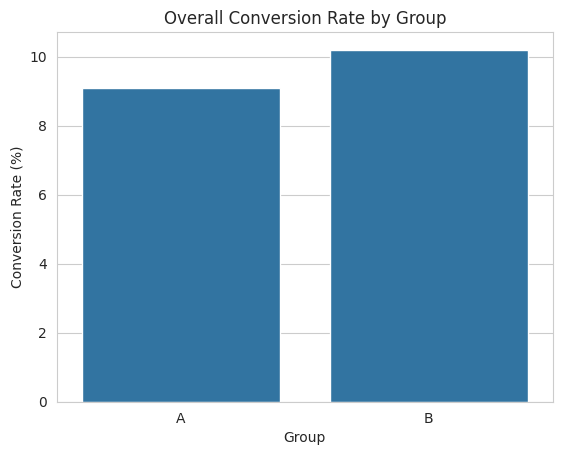

In [81]:
# Plot overall conversion rates
sns.barplot(
    data=summary.reset_index(),
    x="group",
    y="conversion_rate",
    errorbar=None
)

plt.title("Overall Conversion Rate by Group")
plt.xlabel("Group")
plt.ylabel("Conversion Rate (%)")
plt.show()

### Statistical Results Interpretation

Group B achieved a **10.20% conversion rate**, compared with **9.10% for Group A**, generating approximately **12% more conversions** for the same number of visitors.

The difference is statistically significant (p-value < 0.05), and the 95% confidence interval suggests Group B's conversion rate is between **0.76 and 1.45 percentage points higher** than Group A's.

**Business Implications:**  
Group B could help increase customer acquisition and revenue.   
However, before launching, we recommend investigating the Sample Ratio Mismatch (SRM) warning, checking whether the improvement is consistent across weekdays and weekends, and evaluating other business metrics, such as refunds, revenue per customer, and profitability, to ensure the improvement delivers real business value.